# Ballon d'Or 2026 — EDA, preparation and modelling

Companion to `ballon_dor_2026_modelling_spec.md`. This notebook grows step by step.

## A. Load and describe
Goal of this step: load both snapshots and see what we have — shape, size, data types and how much data is there. No cleaning, no features, no modelling yet.

In [1]:
import hashlib
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

SEED = 7
T1_PATH = Path("player_snapshot_t1.csv")
T2_PATH = Path("player_snapshot_t2.csv")
TARGET_COLS = ["bdo_points", "bdo_rank", "vote_share"]
FORECAST_EDITION = 2026

np.random.seed(SEED)
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")

def sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()

commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()
print("git commit :", commit)
print("pandas     :", pd.__version__, "| numpy:", np.__version__)
for p in (T1_PATH, T2_PATH):
    print(f"{p.name:26s} sha256={sha256(p)[:16]}...")

git commit : 4b192ae
pandas     : 3.0.6 | numpy: 2.5.4
player_snapshot_t1.csv     sha256=249bb1ac9a623070...
player_snapshot_t2.csv     sha256=f9af1fd20747536e...


In [2]:
t1 = pd.read_csv(T1_PATH)
t2 = pd.read_csv(T2_PATH)
print("Loaded.")

Loaded.


### A1. Shape and size

In [3]:
size = pd.DataFrame({
    "rows": [len(t1), len(t2)],
    "columns": [t1.shape[1], t2.shape[1]],
    "cells": [t1.size, t2.size],
    "file_size_kb": [T1_PATH.stat().st_size / 1024, T2_PATH.stat().st_size / 1024],
    "memory_kb": [t1.memory_usage(deep=True).sum() / 1024, t2.memory_usage(deep=True).sum() / 1024],
}, index=["T1", "T2"]).round(1)
display(size)

extra = [c for c in t2.columns if c not in t1.columns]
missing_from_t2 = [c for c in t1.columns if c not in t2.columns]
print(f"T2 has {len(extra)} extra columns (post-window block); T1 columns missing from T2: {missing_from_t2}")
print(extra)

,rows,columns,cells,file_size_kb,memory_kb
T1,150,91,13650,102.3,186.9
T2,150,111,16650,130.3,208.3


T2 has 20 extra columns (post-window block); T1 columns missing from T2: []
['wiki_views_post', 'wiki_views_post_juror_w', 'wiki_views_final14', 'wiki_views_final14_juror_w', 'news_vol_post', 'news_vol_post_juror_w', 'news_coverage_ratio_post', 'news_tone_post', 'news_headlines_scored_post', 'post_minutes', 'post_apps', 'post_goal_contribs', 'post_npxg_xa_p90', 'post_npxg_xa_p90_opp_adj', 'post_avg_rating', 'post_big_game_rating', 'post_ucl_goal_contribs', 'post_intl_goal_contribs', 'post_transfer', 'post_injury']


### A2. Data types

In [4]:
def dtype_group(s: pd.Series) -> str:
    if pd.api.types.is_bool_dtype(s):
        return "bool"
    if pd.api.types.is_integer_dtype(s):
        return "integer"
    if pd.api.types.is_float_dtype(s):
        return "float"
    return "text/object"

counts = pd.DataFrame({
    "T1": t1.apply(dtype_group).value_counts(),
    "T2": t2.apply(dtype_group).value_counts(),
}).fillna(0).astype(int)
display(counts)

,T1,T2
bool,13,15
float,30,40
integer,34,42
text/object,14,14


In [5]:
BLOCKS = {
    "identity": ["edition", "snapshot", "snapshot_date", "player_key", "player_name", "nationality", "position_group",
                 "age_at_window_end", "is_goalkeeper", "club_key", "club_team_id", "league_key", "built_at", "pipeline_version"],
    "targets": TARGET_COLS,
    "history": ["prev_bdo_rank", "career_bdo_podiums_before", "is_defending_winner", "consecutive_podiums"],
    "club_performance": [c for c in t1.columns if c.startswith(("club_minutes", "club_apps", "club_goals", "club_assists",
                         "club_np", "club_xa", "club_xg", "club_avg", "big_game", "ucl_minutes", "ucl_goal", "ucl_ko"))],
    "international": [c for c in t1.columns if c.startswith(("intl_", "tourn_", "finals_", "final_", "scored_winner"))],
    "honors": ["won_ucl", "won_league", "won_domestic_cup", "won_world_cup", "won_continental", "won_other_uefa",
               "ucl_back_to_back", "league_poty", "club_trophies_n"],
    "team_context": ["league_finish", "league_n_teams", "league_finish_partial", "ucl_stage_reached", "club_rating_window_end",
                     "club_rating_rank_window_end", "club_rating_fallback", "uefa_country_coeff_rank", "league_mean_rating",
                     "nt_fifa_rank_window_end", "nt_elo_window_end", "nt_tourn_stage_reached"],
    "attention": [c for c in t1.columns if c.startswith(("wiki_", "news_"))],
    "voter_context": ["jurors_same_nation", "jurors_same_confed", "jurors_league_country", "teammates_on_shortlist",
                      "nat_teammates_on_shortlist"],
    "post_window_T2_only": extra,
}
assigned = [c for cols in BLOCKS.values() for c in cols]
unassigned = [c for c in t2.columns if c not in assigned]
dupes = pd.Series(assigned).loc[lambda s: s.duplicated()].tolist()
print("unassigned columns:", unassigned)
print("columns in more than one block:", dupes)

unassigned columns: []
columns in more than one block: []


In [6]:
block_of = {c: b for b, cols in BLOCKS.items() for c in cols[::-1]}
profile = pd.DataFrame({
    "block": pd.Series(block_of),
    "dtype": t2.dtypes.astype(str),
    "non_null": t2.notna().sum(),
    "null": t2.isna().sum(),
    "null_%": (t2.isna().mean() * 100).round(1),
    "n_unique": t2.nunique(),
}).loc[t2.columns]
profile.insert(0, "in_T1", [c in t1.columns for c in profile.index])
display(profile)

,in_T1,block,dtype,non_null,null,null_%,n_unique
edition,True,identity,int64,150,0,0.0,5
snapshot,True,identity,str,150,0,0.0,1
snapshot_date,True,identity,str,150,0,0.0,5
player_key,True,identity,str,150,0,0.0,91
player_name,True,identity,str,150,0,0.0,91
nationality,True,identity,str,150,0,0.0,33
position_group,True,identity,str,150,0,0.0,4
age_at_window_end,True,identity,float64,150,0,0.0,97
is_goalkeeper,True,identity,bool,150,0,0.0,2
bdo_points,True,targets,float64,120,30,20.0,71


### A3. How much data is there?

In [7]:
per_edition = pd.concat({"T1": t1, "T2": t2}).reset_index(level=0).rename(columns={"level_0": "table"})
rows = per_edition.groupby(["edition", "table"]).size().unstack()
rows["role"] = np.where(rows.index == FORECAST_EDITION, "forecast (targets null)", "train / back-test")
display(rows)

uniq = pd.Series({
    "player-season rows": len(t1),
    "distinct players": t1["player_key"].nunique(),
    "distinct clubs": t1["club_key"].nunique(),
    "distinct nationalities": t1["nationality"].nunique(),
    "distinct leagues": t1["league_key"].nunique(),
})
display(uniq.to_frame("count"))

appearances = t1.groupby("player_key").size()
print("Nominations per player (how many players appear in 1, 2, ... 5 editions):")
display(appearances.value_counts().sort_index().rename_axis("editions_nominated").to_frame("players"))

table,T1,T2,role
edition,,,
2022,30,30,train / back-test
2023,30,30,train / back-test
2024,30,30,train / back-test
2025,30,30,train / back-test
2026,30,30,forecast (targets null)


,count
player-season rows,150
distinct players,91
distinct clubs,31
distinct nationalities,33
distinct leagues,9


Nominations per player (how many players appear in 1, 2, ... 5 editions):


,players
editions_nominated,
1,55
2,23
3,7
4,2
5,4


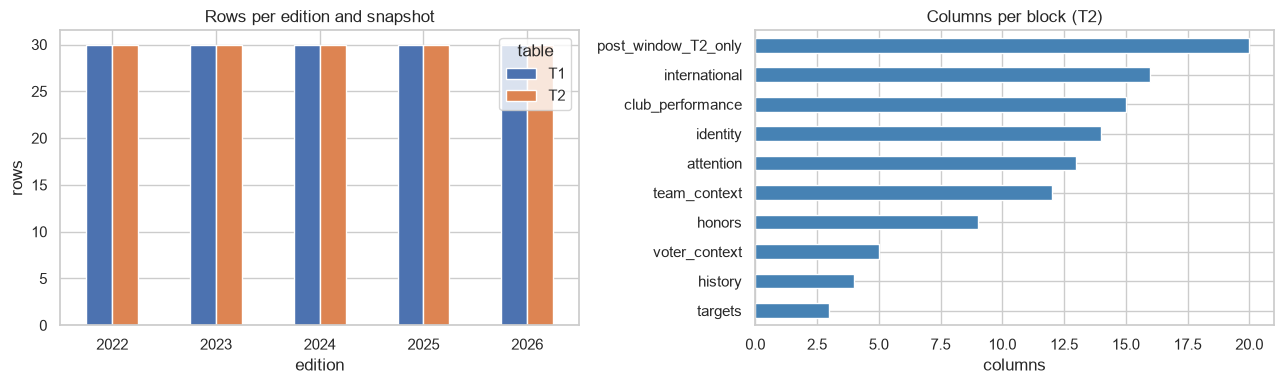

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
rows[["T1", "T2"]].plot.bar(ax=axes[0], rot=0)
axes[0].set_title("Rows per edition and snapshot")
axes[0].set_ylabel("rows")
block_sizes = pd.Series({b: len([c for c in cols if c in t2.columns]) for b, cols in BLOCKS.items()}).sort_values()
block_sizes.plot.barh(ax=axes[1], color="steelblue")
axes[1].set_title("Columns per block (T2)")
axes[1].set_xlabel("columns")
plt.tight_layout()
Path("figures/eda").mkdir(parents=True, exist_ok=True)
plt.savefig("figures/eda/a_size_overview.png", dpi=150)
plt.show()

### A4. First look

In [9]:
display(t1.head(8).T.head(45))

,0,1,2,3,4,5,6,7
edition,2022,2022,2022,2022,2022,2022,2022,2022
snapshot,T1,T1,T1,T1,T1,T1,T1,T1
snapshot_date,2022-07-31,2022-07-31,2022-07-31,2022-07-31,2022-07-31,2022-07-31,2022-07-31,2022-07-31
player_key,p_q11571,p_q133903,p_q1354960,p_q13865408,p_q151269,p_q15521306,p_q17274709,p_q1912
player_name,Cristiano Ronaldo,Virgil van Dijk,Mohamed Salah,Joshua Kimmich,Robert Lewandowski,Bernardo Silva,Mike Maignan,Karim Benzema
nationality,Portugal,Netherlands,Egypt,Germany,Poland,Portugal,France,France
position_group,FWD,DEF,FWD,MID,FWD,MID,GK,FWD
age_at_window_end,37.5,31.1,30.1,27.5,33.9,28.0,27.1,34.6
is_goalkeeper,False,False,False,False,False,False,True,False
bdo_points,0.0,1.0,116.0,0.0,170.0,0.0,0.0,549.0


In [10]:
cats = ["position_group", "ucl_stage_reached", "nt_tourn_stage_reached", "tourn_individual_award", "tourn_name", "league_key"]
for c in cats:
    print(f"--- {c}")
    print(t1[c].value_counts(dropna=False).to_string())
    print()

--- position_group
position_group
FWD    70
MID    47
DEF    26
GK      7

--- ucl_stage_reached
ucl_stage_reached
winner          35
QF              29
R16             21
SF              21
NaN             19
final           15
league_phase     7
playoff          3

--- nt_tourn_stage_reached
nt_tourn_stage_reached
NaN       67
winner    18
QF        15
SF        15
R16       14
final     12
group      7
R32        2

--- tourn_individual_award
tourn_individual_award
NaN                            128
Player of the Tournament        11
Best young player                6
Golden Boot winner (Europe)      5

--- tourn_name
tourn_name
NaN                      67
World Cup                52
EURO                     22
Africa Cup of Nations     5
Copa America              4

--- league_key
league_key
47     49
87     33
53     23
54     22
55     16
61      3
536     2
57      1
130     1



In [11]:
key_numeric = ["age_at_window_end", "club_minutes", "club_npxg_xa_p90_opp_adj", "club_avg_rating", "intl_minutes",
               "club_rating_window_end", "wiki_views_in", "news_vol_in", "bdo_points", "vote_share"]
display(t1[key_numeric].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
age_at_window_end,150.0,27.30,4.41,17.10,24.10,27.00,30.18,39.10
club_minutes,150.0,3700.02,634.89,1713.00,3243.50,3805.50,4152.75,5015.00
club_npxg_xa_p90_opp_adj,150.0,0.43,0.28,-0.13,0.20,0.45,0.65,1.08
club_avg_rating,150.0,7.63,0.33,6.52,7.45,7.64,7.85,8.45
intl_minutes,150.0,639.80,283.70,0.00,452.25,625.00,817.00,1440.00
club_rating_window_end,148.0,1948.09,101.76,1639.00,1886.00,1963.50,2026.00,2111.00
wiki_views_in,150.0,6179451.23,8449058.89,960376.00,2297207.25,3529510.50,6296706.50,67307175.00
news_vol_in,150.0,10930.54,11715.03,1167.39,3548.18,7184.54,14120.90,79168.22
bdo_points,120.0,135.78,262.15,0.00,3.75,20.00,117.75,1380.00
vote_share,120.0,0.03,0.06,0.00,0.00,0.01,0.03,0.37


### A5. Quick sanity checks (printed only, nothing is modified)

In [12]:
print("(edition, player_key) unique in T1:", not t1.duplicated(["edition", "player_key"]).any())
print("(edition, player_key) unique in T2:", not t2.duplicated(["edition", "player_key"]).any())
shared = t1.columns
print("T1 in-window columns identical in T2:",
      t1.reset_index(drop=True).equals(t2[shared].reset_index(drop=True)) or
      t1.sort_values(["edition", "player_key"]).reset_index(drop=True).drop(columns=["snapshot", "snapshot_date"]).equals(
          t2.sort_values(["edition", "player_key"]).reset_index(drop=True)[shared].drop(columns=["snapshot", "snapshot_date"])))
print("2026 target columns entirely null:", bool(t1.loc[t1.edition == FORECAST_EDITION, TARGET_COLS].isna().all().all()))
print("2022-25 target columns have no nulls:", bool(t1.loc[t1.edition < FORECAST_EDITION, TARGET_COLS].notna().all().all()))

(edition, player_key) unique in T1: True
(edition, player_key) unique in T2: True
T1 in-window columns identical in T2: True
2026 target columns entirely null: True
2022-25 target columns have no nulls: True
